# 🌸 Classification with Logistic Regression
**Task:** Build a decision tree classifier and logistic regression to predict a categorical outcome (e.g., species of flowers).  
**Requirements:** Preprocess data, evaluate metrics (accuracy, precision, recall, ROC curve), and compare classifiers.  
**Tools:** `pandas`, `scikit-learn`, `matplotlib`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, RocCurveDisplay
import warnings
warnings.filterwarnings('ignore')

# We will use the Iris dataset from Level 1. 
# To plot a standard ROC curve easily, we will filter it to a Binary Classification problem (2 species).
data_path = 'data/iris.csv'
try:
    df = pd.read_csv(data_path)
    df = df[df['species'] != 'setosa'] # Keep only versicolor and virginica for binary classification
    print('✅ Data loaded successfully')
except:
    from sklearn.datasets import load_iris
    data = load_iris()
    df = pd.DataFrame(data.data, columns=data.feature_names)
    df['species'] = data.target
    df = df[df['species'] != 0]
    print('⚠️ Used sklearn built-in Iris data')

display(df.head())

✅ Data loaded successfully


,sepal_length,sepal_width,petal_length,petal_width,species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
53,5.5,2.3,4.0,1.3,versicolor
54,6.5,2.8,4.6,1.5,versicolor


In [2]:
# Preprocessing: Scaling and Encoding
X = df.drop(columns=['species'] if 'species' in df.columns else [df.columns[-1]])
y = df['species'] if 'species' in df.columns else df.iloc[:, -1]

# Encode target labels to 0 and 1
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)
print(f'✅ Data split: Train {X_train.shape}, Test {X_test.shape}')

✅ Data split: Train (80, 4), Test (20, 4)


In [3]:
# Train Logistic Regression
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

y_pred_log = log_reg.predict(X_test)
print("--- Logistic Regression Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log):.2f}")
print(classification_report(y_test, y_pred_log, target_names=le.classes_.astype(str)))

--- Logistic Regression Performance ---
Accuracy: 0.85
              precision    recall  f1-score   support

  versicolor       0.91      0.83      0.87        12
   virginica       0.78      0.88      0.82         8

    accuracy                           0.85        20
   macro avg       0.84      0.85      0.85        20
weighted avg       0.86      0.85      0.85        20



In [4]:
# Compare with Random Forest and SVM
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"\n--- {name} Performance ---")
    print(f"Accuracy: {accuracy_score(y_test, preds):.2f}")
    print(classification_report(y_test, preds, target_names=le.classes_.astype(str)))


--- Random Forest Performance ---
Accuracy: 0.95
              precision    recall  f1-score   support

  versicolor       1.00      0.92      0.96        12
   virginica       0.89      1.00      0.94         8

    accuracy                           0.95        20
   macro avg       0.94      0.96      0.95        20
weighted avg       0.96      0.95      0.95        20


--- SVM Performance ---
Accuracy: 0.90
              precision    recall  f1-score   support

  versicolor       1.00      0.83      0.91        12
   virginica       0.80      1.00      0.89         8

    accuracy                           0.90        20
   macro avg       0.90      0.92      0.90        20
weighted avg       0.92      0.90      0.90        20



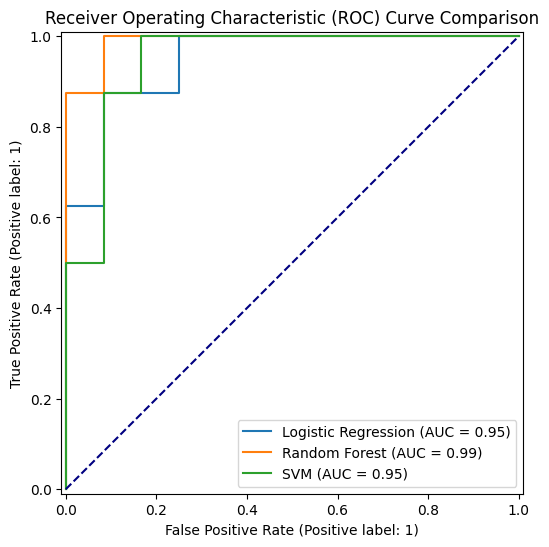

In [5]:
# ROC Curve Comparison
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=ax, name='Logistic Regression')
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)

plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison')
plt.show()

In [6]:
import joblib
import os
import pandas as pd

os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save logistic regression, SVM classifier, and scaler
joblib.dump(log_reg, 'models/logistic_model.pkl')
joblib.dump(models['SVM'], 'models/classifier_svm.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(le, 'models/label_encoder.pkl')

# Save test predictions
output_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_log})
output_df.to_csv('outputs/classification_predictions.csv', index=False)
print('✅ Saved models and outputs successfully!')

✅ Saved models and outputs successfully!
